# CNN Model - Face Mask Detection System

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

## Loading the Dataset and Visualize

**Dataset**  
with_mask: 3725  
without_mask: 3828  
Total: 7553

In [2]:
DATASET_PATH = "dataset"
BATCH_SIZE = 32             # Number of images to process in a batch
IMG_SIZE = (128, 128)       # Resize images to this size

In [ ]:
# 80% for training, 20% for testing

train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split = 0.2,
    subset = "training",
    seed = 123,             # For reproducibility
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = "binary"   # Encodes labels as 0 and 1
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split = 0.2,
    subset = "validation",
    seed = 123,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = "binary"
)

Found 7553 files belonging to 2 classes.
Using 6043 files for training.
Found 7553 files belonging to 2 classes.
Using 1510 files for validation.


In [4]:
class_names = train_dataset.class_names
print("Class names:", class_names)

Class names: ['with_mask', 'without_mask']


In [ ]:
# Display the shape of the training and test datasets
for image_batch, label_batch in train_dataset.take(1):
    print("Training images batch shape:", image_batch.shape)    # batch_size, img_height, img_width, num_channels
    print("Training labels batch shape:", label_batch.shape)    # 32 labels (one for each image in the batch)

for image_batch, label_batch in test_dataset.take(1):
    print("Test images batch shape:", image_batch.shape)
    print("Test labels batch shape:", label_batch.shape)

Training images batch shape: (32, 128, 128, 3)
Training labels batch shape: (32, 1)
Test images batch shape: (32, 128, 128, 3)
Test labels batch shape: (32, 1)


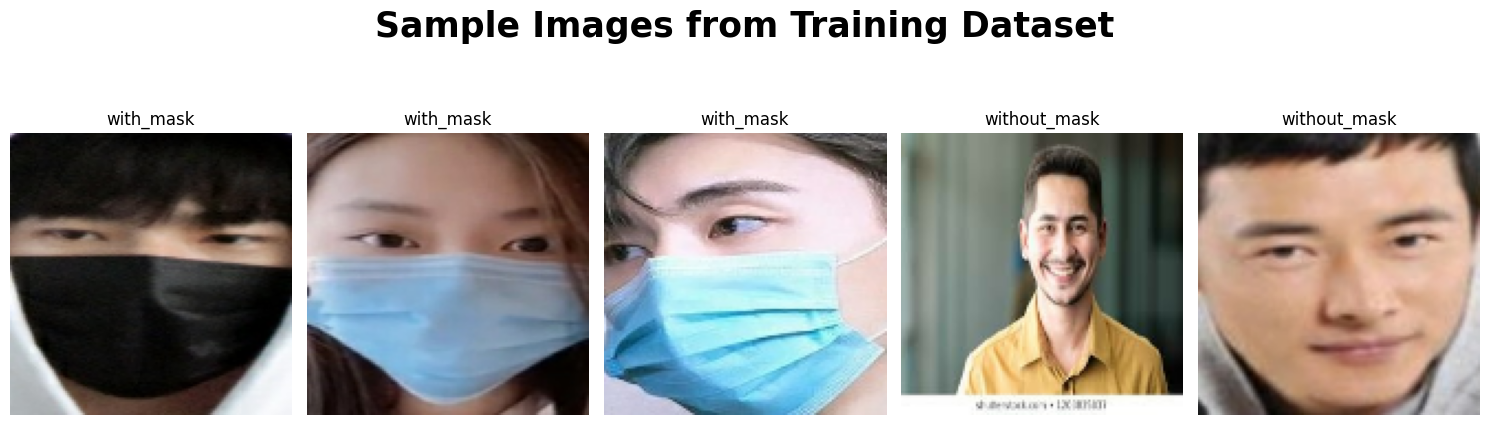

In [ ]:
# Visualize five sample images with labels
plt.figure(figsize=(15, 5))

for images, labels in train_dataset.take(1):
    for i in range(5):
        plt.subplot(1, 5, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))   # Convert tensor to uint8 for plotting
        plt.title(class_names[int(labels[i][0])])       # Use the label (0 or 1) to get the correct class name
        
        plt.suptitle("Sample Images from Training Dataset", fontsize=25, fontweight='bold')
        plt.axis("off")
        plt.tight_layout()  # Adjust the spacing between subplots

plt.show()

## Data Preprocessing and Augmentation

In [ ]:
data_preprocessing_and_augmentation = tf.keras.Sequential([
    # Resize images to a fixed size
    layers.Resizing(IMG_SIZE[0], IMG_SIZE[1]),

    # Normalize pixel values between 0 and 1
    layers.Rescaling(1./255),

    # Applying basic data augmentation (flipping and rotation)
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1)  # Rotate images by up to 10%
])

print("Preprocessing and augmentation pipeline created successfully.")

Preprocessing and augmentation pipeline created successfully.


## Create, Train, and Save the CNN Model

In [ ]:
# Create the Convolutional Neural Network (CNN) model
model = models.Sequential([
    # 1. Preprocessing and Augmentation Block
    data_preprocessing_and_augmentation,

    # 2. First Convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),   # 32 filters, 3x3 kernel size, ReLU activation
    layers.MaxPooling2D(pool_size=(2, 2)),

    # 3. Second Convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    
    # 4. Third Convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # 5. Flatten and Fully Connected Layers
    layers.Flatten(),                               # convert 3D feature maps to 1D feature vector
    layers.Dense(128, activation='relu'),

    # 6. Randomly turns off 50% of neurons during training to prevent memorization (overfitting)
    layers.Dropout(0.5),

    # 7. Output Layer (1 node with Sigmoid for binary classification)
    layers.Dense(1, activation='sigmoid')
])

In [22]:
# Compile the model
model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

In [23]:
# Build the model with the specified input shape & display the model architecture
model.build(input_shape=(None, IMG_SIZE[0], IMG_SIZE[1], 3))
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# Train the model
EPOCHS = 20     # Number of times to iterate over the entire training dataset

print("Starting model training...")
history = model.fit(
    train_dataset,
    validation_data = test_dataset,
    epochs = EPOCHS
)

Starting model training...
Epoch 1/20
189/189 ━━━━━━━━━━━━━━━━━━━━ 192s 986ms/step - accuracy: 0.8367 - loss: 0.3720 - val_accuracy: 0.9053 - val_loss: 0.2261
Epoch 2/20
189/189 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - accuracy: 0.8905 - loss: 0.2764 - val_accuracy: 0.9185 - val_loss: 0.2123
Epoch 3/20
189/189 ━━━━━━━━━━━━━━━━━━━━ 182s 961ms/step - accuracy: 0.9065 - loss: 0.2367 - val_accuracy: 0.9404 - val_loss: 0.1877
Epoch 4/20
189/189 ━━━━━━━━━━━━━━━━━━━━ 193s 1s/step - accuracy: 0.9174 - loss: 0.2102 - val_accuracy: 0.9358 - val_loss: 0.1660
Epoch 5/20
189/189 ━━━━━━━━━━━━━━━━━━━━ 199s 1s/step - accuracy: 0.9202 - loss: 0.2093 - val_accuracy: 0.9040 - val_loss: 0.2560
Epoch 6/20
189/189 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - accuracy: 0.9207 - loss: 0.2091 - val_accuracy: 0.9358 - val_loss: 0.1539
Epoch 7/20
189/189 ━━━━━━━━━━━━━━━━━━━━ 183s 968ms/step - accuracy: 0.9343 - loss: 0.1808 - val_accuracy: 0.9536 - val_loss: 0.1277
Epoch 8/20
189/189 ━━━━━━━━━━━━━━━━━━━━ 182s 962ms/step - acc

accuracy: 0.9676  
loss: 0.0922  
val_accuracy: 0.9695  
val_loss: 0.0704

In [30]:
# Save the model
MODEL_SAVE_PATH = "face_mask_detector.keras"
model.save(MODEL_SAVE_PATH)
print(f"Model successfully saved to {MODEL_SAVE_PATH}.")

Model successfully saved to face_mask_detector.keras.


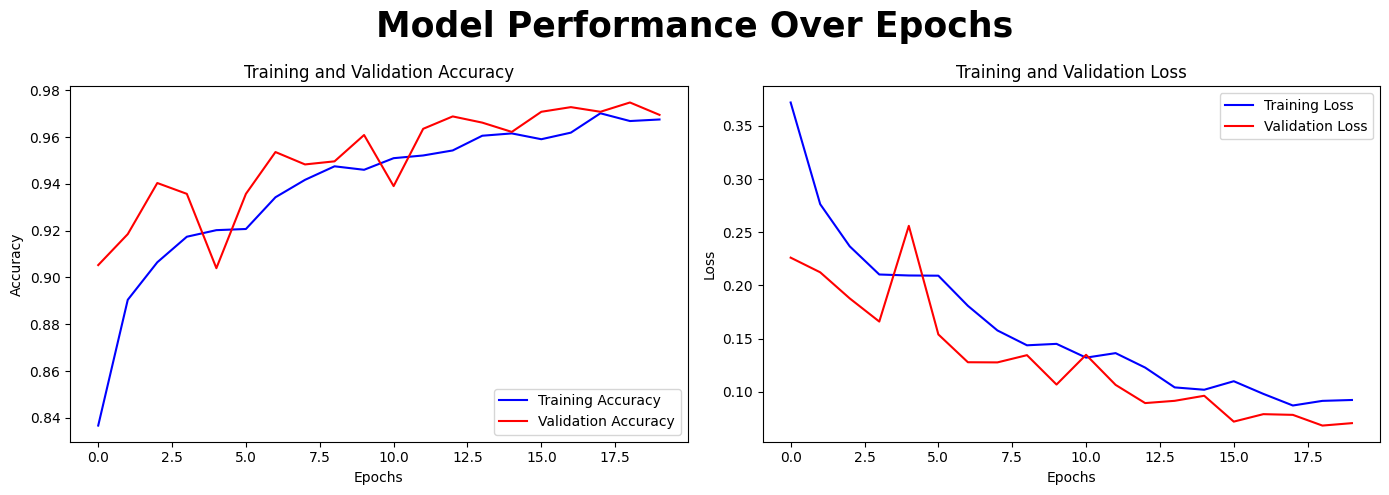

In [31]:
# Visualize Model Performance
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(EPOCHS)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'b-', label='Training Accuracy')
plt.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'b-', label='Training Loss')
plt.plot(epochs_range, val_loss, 'r-', label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.suptitle("Model Performance Over Epochs", fontsize=25, fontweight='bold')

plt.tight_layout()
plt.show()

## Testing the CNN Model

In [1]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [3]:
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import load_img, img_to_array

loaded_model = load_model('../face_mask_detector.keras')
print("Model loaded successfully!\n")

Model loaded successfully!



In [ ]:
loaded_model.summary()
# loaded_model.get_weights()
# loaded_model.optimizer

Face Detect from Live Webcam

In [23]:
import cv2
import numpy as np

face_model = cv2.CascadeClassifier('./haarcascade_frontalface_default.xml')
if face_model.empty():
    print("Error loading Haar Cascade XML file.")

cam = cv2.VideoCapture(0) # external webcam (change to 0 for built-in webcam)
if not cam.isOpened():
    print("Error: Could not open webcam.")

while True:
    success, frame = cam.read()
    if not success:
        print("Error: Could not read frame from webcam.")
        break

    gray_img = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    faces = face_model.detectMultiScale(gray_img, scaleFactor=1.1, minNeighbors=5)

    IMG_SIZE = (128, 128)  # Must match the input size used during training
    for (x, y, w, h) in faces:
        face_img = frame[y:y+h, x:x+w]
        face_img = cv2.resize(face_img, (128, 128))
        face_img = cv2.cvtColor(face_img, cv2.COLOR_BGR2RGB)
        face_img = face_img.astype("float32") / 255.0
        input_face = np.expand_dims(face_img, axis=0)

        prediction = loaded_model.predict(input_face)
        label = "Mask" if prediction[0][0] >= 0.5 else "No Mask"
        color = (0, 255, 0) if label == "Mask" else (0, 0, 255)

        cv2.rectangle(frame, (x, y), (x+w, y+h), color, 2)
        cv2.putText(frame, label, (x, y-10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, 2)
    
    cv2.imshow("Face Mask Detection", frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break
    
cam.release()
cv2.destroyAllWindows()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━

In [10]:
def test_image(image_path, model, image_size=(128, 128)):    
    # Load the image and resize it to match the model's expected input
    img = load_img(image_path, target_size=image_size)
    
    # Convert the image to a NumPy array
    img_array = img_to_array(img)
    
    # Add a "batch" dimension. 
    # The model expects batches of images (e.g., shape: 32, 224, 224, 3).
    # This turns our single image into a batch of 1 (shape: 1, 224, 224, 3).
    img_array = tf.expand_dims(img_array, 0) 
    
    # Make the prediction!
    # The output will be a single probability between 0.0 and 1.0
    prediction = model.predict(img_array)
    score = prediction[0][0]
    
    # Interpret the result
    # Assuming standard alphabetical folder loading: 
    # Class 0 = "with_mask", Class 1 = "without_mask"
    if score >= 0.5:
        label = "No Mask"
        confidence = score * 100
    else:
        label = "Mask"
        # Invert the score to get the confidence for the "Mask" class
        confidence = (1 - score) * 100 
        
    # Display the image with the prediction
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"Prediction: {label} ({confidence:.2f}%)")
    plt.axis("off")
    plt.show()

In [15]:
import matplotlib.pyplot as plt

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 375ms/step


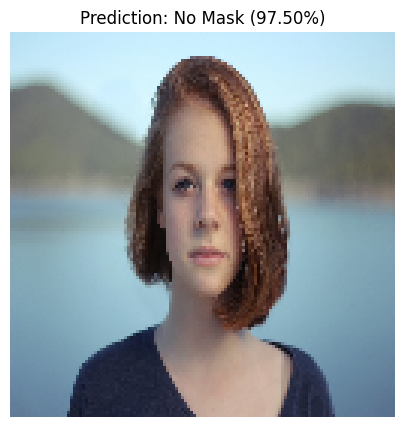

In [22]:
TEST_IMAGE_PATH = '../image.png' 
test_image(TEST_IMAGE_PATH, loaded_model, image_size=(128, 128))